# **Preparing Dependancies**

In [3]:
!pip install -q diffusers transformers accelerate safetensors

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from diffusers import StableDiffusionInpaintPipeline

from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionImg2ImgPipeline,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
    DDIMScheduler
)

# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [4]:
model_id = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    dtype=torch.float16,
    use_safetensors=True,
    safety_checker=None
)

pipe = pipe.to("cuda")
pipe.enable_attention_slicing()

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


## **Generate Image**

  0%|          | 0/50 [00:00<?, ?it/s]

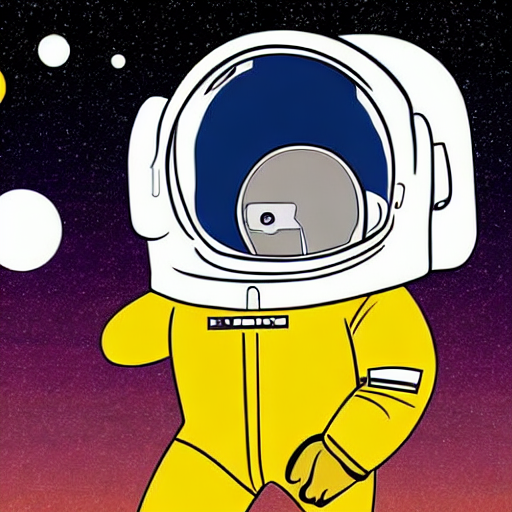

In [5]:
prompt = "an astronaut wearing a white spacesuit standing on the moon, Earth in the background, a black sky filled with stars, clean 2D illustration, bold outlines, flat colors"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
seed = 222

def generate_simple_image(prompt, negative_prompt, seed):
    generator = torch.Generator("cuda").manual_seed(seed)

    simple_image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator
    ).images[0]

    return simple_image

hasil_simple_image = generate_simple_image(prompt, negative_prompt, seed)
hasil_simple_image

## **Generate Image with Hyperparameter Configuration**

  0%|          | 0/75 [00:00<?, ?it/s]

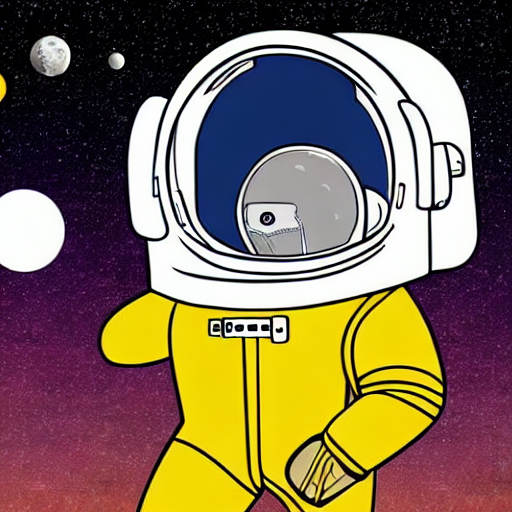

In [6]:
seed = 222
num = 75
scale = 7.5

def generate_advanced_image(prompt, negative_prompt, seed, scale, num):
    generator = torch.Generator("cuda").manual_seed(seed)

    advanced_image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=scale,
        num_inference_steps=num
    ).images[0]

    return advanced_image

hasil_advanced_image = generate_advanced_image(prompt, negative_prompt, seed, scale, num)
hasil_advanced_image

## **Guidance Scale Comparison**

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

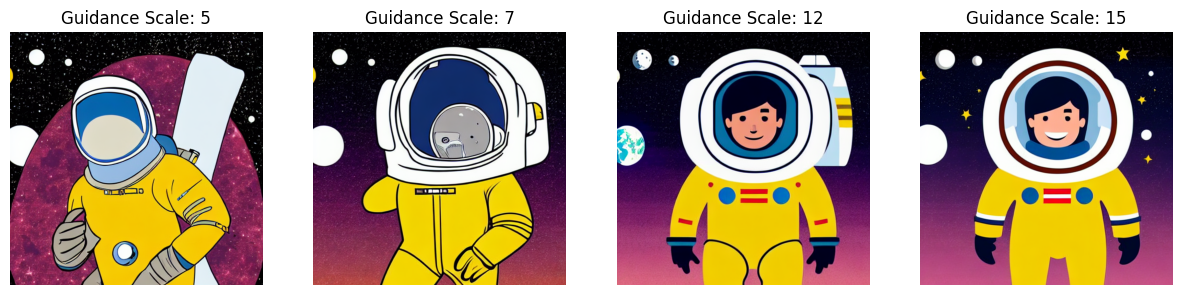

In [7]:
guidance_scales = [5, 7, 12, 15]
images = []

for scale in guidance_scales:
    generator = torch.Generator("cuda").manual_seed(222)
    img = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        guidance_scale=scale,
        generator=generator
    ).images[0]
    images.append(img)

plt.figure(figsize=(15, 5))
for i, img in enumerate(images):
    plt.subplot(1, len(images), i + 1)
    plt.imshow(img)
    plt.title(f"Guidance Scale: {guidance_scales[i]}")
    plt.axis("off")
plt.show()

### **Guidance Scale Explanation:**

*   **Gambar dengan "Scale" Rendah:**   
*"Saat nilai scale rendah gambar yang dihasilkan jauh lebih bagus dibandingkan dengan nilai yang lebih tinggi. Tetapi ada tidaknya kesesuaian antara prompt dengan gambar yang dihasilkan."*

*   **Gambar dengan "Scale" Tinggi:**   
*"Berbanding terbalik dengan nilai scale yang rendah, nilai scale yang tinggi mengorbankan visual yang jika dibandingkan dengan nilai scale rendah akan tetapi model sedikit mirip apa yang diminta oleh prompt tidak dengan nilai scale rendah."*

## **Inference Steps Comparison**

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

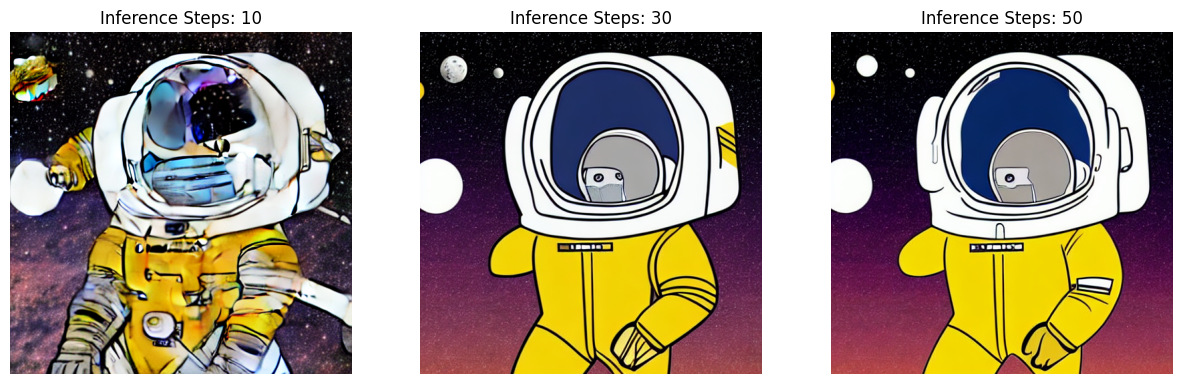

In [8]:
steps_list = [10, 30, 50]
images = []

for steps in steps_list:
    generator = torch.Generator("cuda").manual_seed(222)
    img = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        generator=generator
    ).images[0]
    images.append(img)

plt.figure(figsize=(15, 5))
for i, img in enumerate(images):
    plt.subplot(1, len(images), i + 1)
    plt.imshow(img)
    plt.title(f"Inference Steps: {steps_list[i]}")
    plt.axis("off")
plt.show()

### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah:**  
*"Dengan step rendah gambar yang dihasilkan belum selesai sehingga menghasilkan gambar yang kacau."*
*   **Gambar dengan "Step" Tinggi:**  
*"Kebalikannya, gambar yang dihasilakn menjadi gambar yang bagus dan rapih."*

## **Batch Inference from One Prompt**

  0%|          | 0/30 [00:00<?, ?it/s]

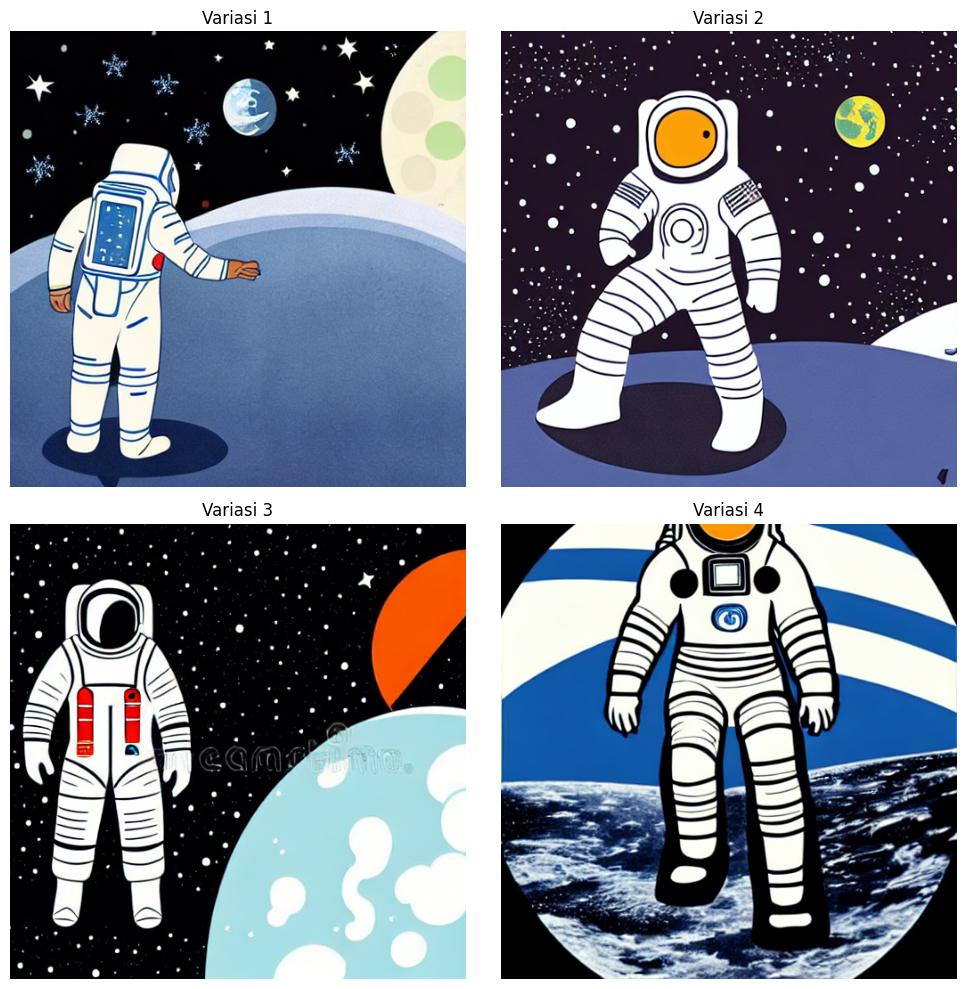

In [9]:
batch_img = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=30,
    generator=generator,
    num_images_per_prompt=4
).images

plt.figure(figsize=(10, 10))

for i, img in enumerate(batch_img):
    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(f"Variasi {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## **Load Scheduler**

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

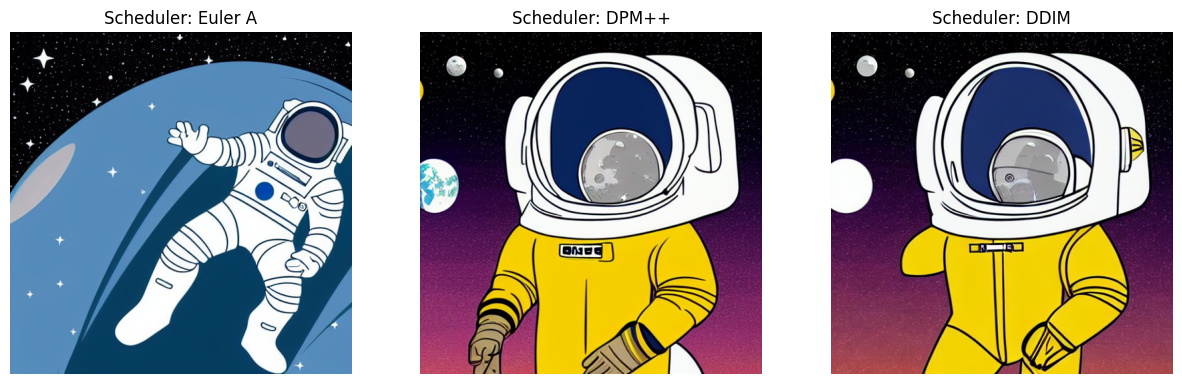

In [10]:
def load_scheduler(pipe, scheduler_name):
    if scheduler_name == "Euler A":
        scheduler = EulerAncestralDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")
    elif scheduler_name == "DPM++":
        scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")
    elif scheduler_name == "DDIM":
        scheduler = DDIMScheduler.from_pretrained(model_id, subfolder="scheduler")

    pipe.scheduler = scheduler
    return pipe

scheduler_configs = ["Euler A", "DPM++", "DDIM"]
images = []

for scheduler in scheduler_configs:
  pipe = load_scheduler(pipe, scheduler)

  generator = torch.Generator("cuda").manual_seed(222)
  img = pipe(
      prompt=prompt,
      negative_prompt=negative_prompt,
      num_inference_steps=steps,
      generator=generator
  ).images[0]
  images.append((scheduler, img))

plt.figure(figsize=(15, 5))
for i, (nama, img) in enumerate(images):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(f"Scheduler: {nama}")
    plt.axis("off")
plt.show()

### **Scheduler Comparation:**

*   **Gambar dengan "Euler A Scheduler":**  
*"Menghasilkan gambar yang warnanya berbeda dari yang lainnya dan terlihat lebih jelas untuk pewarnaanya ditambah ada garis outlinenya."*
*   **Gambar dengan "DPM++ Scheduler":**  
*"Menghasilkan gambar yang warnanya lebih."*
*   **Gambar dengan "DDIM Scheduler":**  
*"Hampir sama yang dihasilkan oleh DPM++ tetapi ada memiliki garis garis tambahan dan ada objek yang berbeda dengan dua scheduler lainnya."*

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Inpainting**

### **Load Model Inpainting**

In [11]:
model_pain = "runwayml/stable-diffusion-inpainting"

pipe = StableDiffusionInpaintPipeline.from_pretrained(
    model_pain,
    torch_dtype=torch.float16,
    safety_checker=None
)

pipe = pipe.to("cuda")
pipe.enable_attention_slicing()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_inpaint.StableDiffusionInpaintPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


### **Manual Masking**

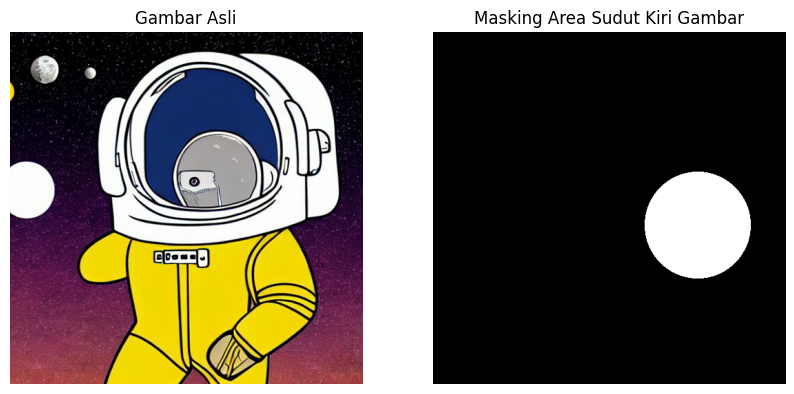

In [12]:
init_image = hasil_advanced_image.convert('RGB')
init_image = init_image.resize((512, 512))
init_image

mask = Image.new(mode="L", size=init_image.size)
mask_draw = ImageDraw.Draw(mask)

width, height = init_image.size
left = width * 0.60
top = height * 0.40
right = width * 0.90
bottom = height * 0.70

mask_draw.ellipse((left, top, right, bottom), fill=255)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(init_image)
plt.title("Gambar Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Masking Area Sudut Kiri Gambar")
plt.axis("off")
plt.show()

### **Generate**

  0%|          | 0/50 [00:00<?, ?it/s]

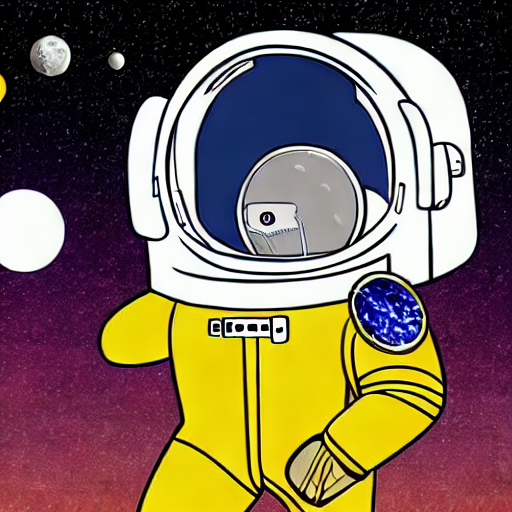

In [13]:
prompt_edit = "a damaged broken satellite crashed on the moon surface, lunar surface with craters, metallic debris, broken panels, exposed mechanical parts, multi-legged landing gear, crashed on Mars surface, highly detailed mechanical structure, sharp focus, realistic scale, photorealistic, cinematic lighting"
negative_edit = "floating, flying, in the sky, cartoon, 2d, illustration, simple, flat, low quality, blurry"

def inpaint_engine(init_image, mask, prompt_edit):
    generator = torch.Generator("cuda").manual_seed(9)

    image_inpainting = pipe(
        prompt=prompt_edit,
        negative_prompt=negative_edit,
        image=init_image,
        mask_image=mask,
        guidance_scale=10,
        num_inference_steps=50,
        strength=1.0,
        generator=generator
    ).images[0]

    return image_inpainting

hasil_inpainting = inpaint_engine(init_image, mask, prompt_edit)
hasil_inpainting

## **Outpainting**

### **Prepare the Canvas**

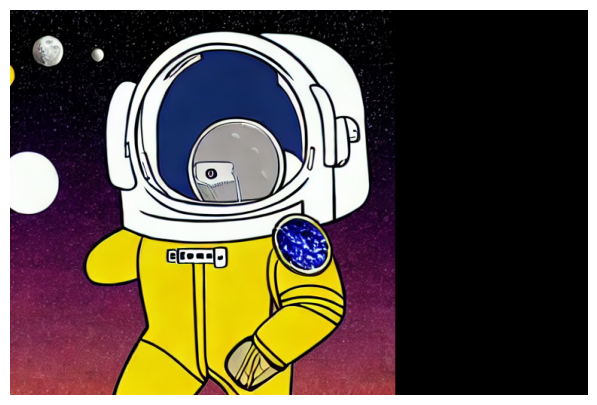

In [14]:
def prepare_outpainting(img_input):
  old_width, old_height = img_input.size
  new_width = old_width + 256

  outpaint_image = Image.new("RGB", (new_width, old_height))
  outpaint_image.paste(img_input, (0, 0))

  outpaint_mask = Image.new("L", (new_width, old_height), 255)

  original_area_mask = Image.new("L", (old_width, old_height), 0)
  outpaint_mask.paste(original_area_mask, (0, 0))

  return outpaint_image, outpaint_mask

gambar_outpaint, mask_outpainting = prepare_outpainting(hasil_inpainting)
gambar_outpaint, mask_outpainting

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gambar_outpaint)

plt.axis("off")

plt.tight_layout()
plt.show()

### **Generate**

Sedang memperluas gambar...


  0%|          | 0/50 [00:00<?, ?it/s]

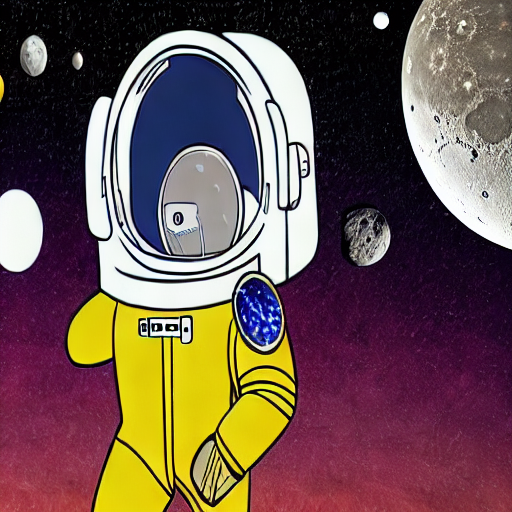

In [15]:
prompt_outpainting = "vast endless lunar landscape with deep craters and scattered moon rocks, dark deep space sky with glowing milky way and bright stars, distant lunar mountains, photorealistic photograph, highly detailed, 8k resolution, cinematic lighting"

print("Sedang memperluas gambar...")

image_outpainting = pipe(
    prompt=prompt_outpainting,
    negative_prompt=negative_prompt,
    image=gambar_outpaint,
    mask_image=mask_outpainting,
    guidance_scale=7.5,
    num_inference_steps=50,
    strength=1.0,
    generator=generator
).images[0]

image_outpainting